# 07. Baselines and Statistical Models

**Procurement Intelligence Platform** | Notebook 07 of 13

The classical toolbox: benchmarks every model must beat, exponential smoothing, Theta, SARIMAX with the maintenance plan, intermittent-demand methods and Prophet.

| | |
|---|---|
| **Inputs** | Section weekly series, known-future covariates |
| **Outputs** | Validation results (2024) for 9 models, statistical champion |
| **Skills shown** | Statistical forecasting, model diagnostics, interpretation of coefficients |

## 1. The models and why each one is here

| Model | Idea | Why it is in the arena |
|---|---|---|
| **Naive** | Next weeks = last week | The minimum bar. Hard to beat on stock-like series |
| **Seasonal Naive** | Next weeks = same week last year | The MASE denominator; captures yearly patterns only |
| **Moving Average (13w)** | Average of the last quarter | What most planners do in Excel today |
| **ETS** | Exponential smoothing with automatic error, trend and seasonality choice | Adapts the level quickly; robust workhorse |
| **Theta** | Decomposes into a long-term trend line and short-term curvature | Won the M3 forecasting competition; strong on noisy data |
| **SARIMAX** | ARIMA errors plus regressors: Fourier terms (season), shutdown, budget push, MRP week and the **planned-maintenance schedule** | Uses information the planner already has |
| **Croston** | Separates demand size and demand interval | Specialist for intermittent demand (challenger at section level) |
| **TSB** | Croston variant that updates the probability of demand every week | Handles obsolescence and changing frequency |
| **Prophet** | Additive trend plus yearly seasonality plus regressors | Popular in industry; easy to explain to managers |

All models are fitted per section (12 series) at every origin, with 80% and 95% prediction intervals. Models without native intervals
(Moving Average, Croston, TSB) receive **conformal intervals** computed from their own past errors.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
from p2p.data import panel
from p2p.forecasting import backtest as bt, models_stats as ms
from p2p.forecasting.registry import run_or_load
from p2p.forecasting.metrics import evaluate, seasonal_naive_scale

df = panel("pr_lines")
train, _ = bt.train_test(df)
scale = seasonal_naive_scale(train)          # MASE denominators, from training data only

models = {**ms.baseline_models(), **ms.statistical_models(), "Prophet": ms.prophet_model()}
results = {name: run_or_load(name, fn, df, bt.validation_cutoffs(), "inflow", "validation") for name, fn in models.items()}
val = pd.concat(results.values(), ignore_index=True)
board = evaluate(val, scale)
board["seconds"] = board.model.map({k: v.attrs["seconds"] for k, v in results.items()})
display(board)

,model,MASE,WAPE,Bias,Pinball,CRPS,Coverage80,Coverage95,seconds
0,SARIMAX (Fourier + PM plan),0.765,0.375,-0.063,1.239,2.477,0.887,0.956,79.380
1,ETS,0.776,0.382,-0.105,1.311,2.623,0.900,0.947,0.832
2,Moving Average (13w),0.793,0.389,-0.049,1.419,2.838,0.698,0.780,0.085
3,Theta,0.796,0.392,-0.034,1.288,2.576,0.895,0.952,1.302
4,Croston,0.796,0.391,-0.042,1.451,2.902,0.694,0.772,0.106
5,Prophet,0.817,0.399,-0.036,1.300,2.601,0.833,0.925,8.627
6,TSB,0.821,0.402,-0.035,1.474,2.948,0.686,0.774,0.087
7,Seasonal Naive,0.954,0.470,-0.098,1.538,3.077,0.906,0.949,0.133
8,Naive,1.103,0.535,0.059,2.007,4.013,0.967,0.992,0.165


> Backtests are cached in `reports/experiments/` by `run_or_load`. Delete the files (or run `python scripts/run_experiments.py`)
> to recompute everything from scratch; the results are deterministic.

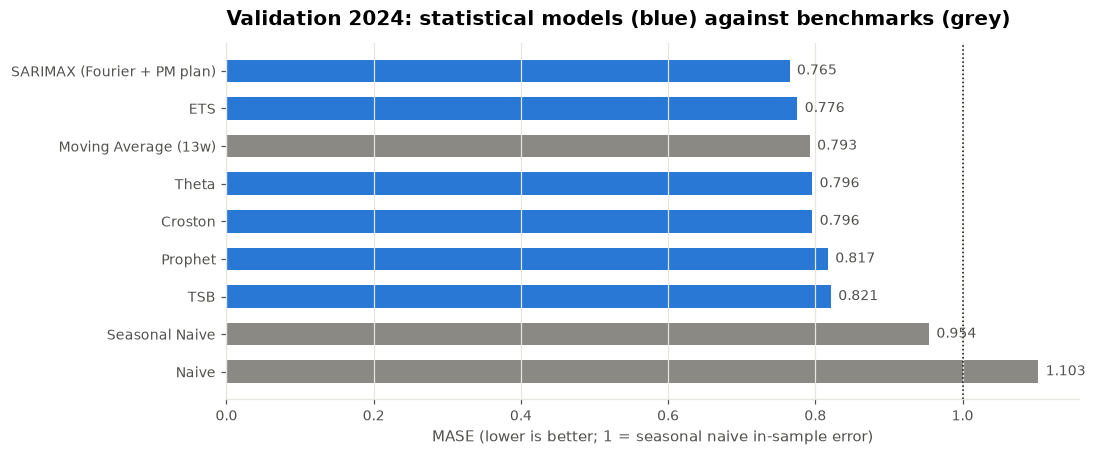

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
b = board.sort_values("MASE", ascending=True)
colors = [SERIES[0] if m not in ("Naive", "Seasonal Naive", "Moving Average (13w)") else BRAND["muted"] for m in b.model]
ax.barh(b.model, b.MASE, color=colors, height=0.6)
ax.axvline(1, color=BRAND["ink"], lw=1, ls=":")
for y, v in enumerate(b.MASE):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=9, color=BRAND["ink_2"])
ax.invert_yaxis(); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("MASE (lower is better; 1 = seasonal naive in-sample error)")
ax.set_title("Validation 2024: statistical models (blue) against benchmarks (grey)")
plt.show()

**What we see.** Every statistical model beats the naive benchmarks. SARIMAX with the maintenance plan has the lowest error among the
classical models, followed by ETS and Theta, all very close. The two intermittent-demand methods sit behind them, as expected: at
section level the demand is not intermittent (notebook 05).

**So what.** The 13-week moving average, which is what a planner typically builds in Excel, is already a fair benchmark. The
statistical models improve on it, but by a few percent, not by half. Weekly section demand contains a lot of noise that no model can
predict (project bursts), so gains will be incremental and must be checked for significance (notebook 11).

## 2. Accuracy by horizon

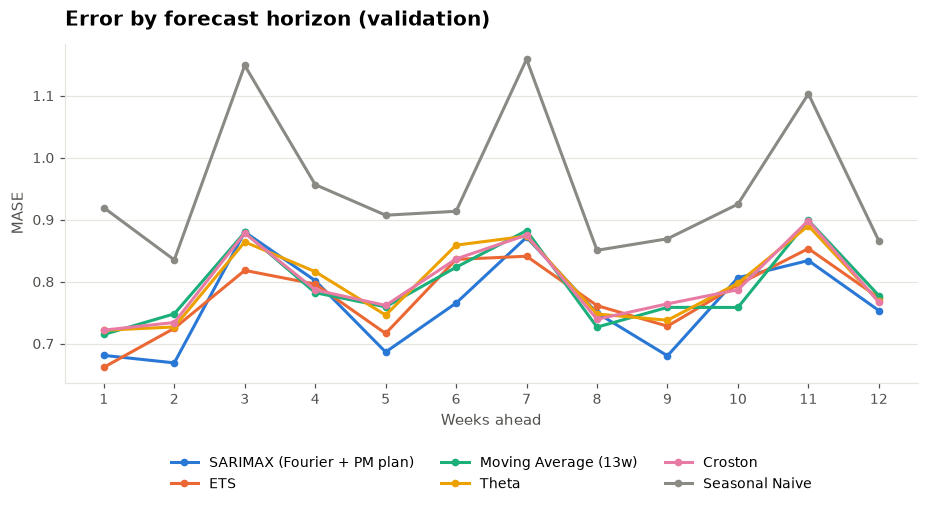

In [4]:
top = board.model.head(5).tolist() + ["Seasonal Naive"]
h_err = val[val.model.isin(top)].assign(ae=lambda d: (d.y - d.yhat).abs() / d.unique_id.map(scale)).groupby(["model", "h"]).ae.mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(top):
    ax.plot(h_err.index, h_err[m], marker="o", ms=4, label=m, color=SERIES[i] if m != "Seasonal Naive" else BRAND["muted"])
ax.set_xlabel("Weeks ahead"); ax.set_ylabel("MASE"); ax.set_xticks(range(1, 13))
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18)); ax.set_title("Error by forecast horizon (validation)")
plt.show()

**What we see.** Errors do not grow with the horizon: demand is a fairly stable level plus noise, so week 12 is not much harder to
forecast than week 1. The zig-zag (peaks at 3, 7 and 11 weeks ahead) is a calendar effect: origins are four weeks apart and planned
maintenance runs on a four-week cycle, so those horizons always land on the same, more volatile position of the cycle. The seasonal
naive is worse at every horizon.

**So what.** A quarterly planning horizon is realistic for this business. Buyers can plan workload a quarter ahead with roughly the same
confidence as next week.

## 3. What a forecast looks like

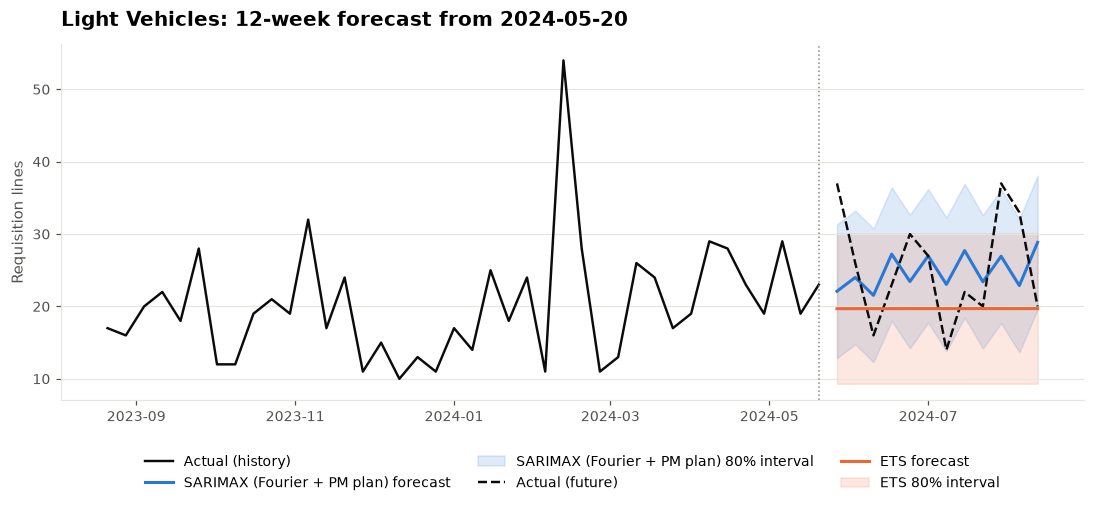

In [5]:
sec, origin = "SEC04", bt.validation_cutoffs()[5]
hist = df[(df.unique_id == sec) & (df.ds <= origin) & (df.ds > origin - pd.Timedelta(weeks=40))]
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(hist.ds, hist.y, color=BRAND["ink"], lw=1.6, label="Actual (history)")
for i, m in enumerate(["SARIMAX (Fourier + PM plan)", "ETS"]):
    f = val[(val.model == m) & (val.unique_id == sec) & (val.cutoff == origin)].sort_values("ds")
    ax.plot(f.ds, f.yhat, color=SERIES[i], lw=2, label=f"{m} forecast")
    ax.fill_between(f.ds, f["q0.1"], f["q0.9"], color=SERIES[i], alpha=0.15, label=f"{m} 80% interval")
    if i == 0:
        ax.plot(f.ds, f.y, color=BRAND["ink"], lw=1.6, ls="--", label="Actual (future)")
ax.axvline(origin, color=BRAND["muted"], ls=":", lw=1)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax.set_ylabel("Requisition lines")
ax.set_title(f"Light Vehicles: 12-week forecast from {origin.date()}")
plt.show()

**What we see.** SARIMAX follows the week-to-week shape (it knows the maintenance plan and the MRP rhythm), while ETS projects a flat
level. Both intervals contain most of the actual weeks.

## 4. Inside SARIMAX: what did the model learn?

In [6]:
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA
from p2p.forecasting.features import known_future_exog

X = known_future_exog()
tr = train[train.unique_id == "SEC04"].merge(X, on=["unique_id", "ds"])
sf = StatsForecast(models=[AutoARIMA(season_length=1)], freq="W-MON").fit(tr)
fitted = sf.fitted_[0, 0].model_
coef = pd.Series(fitted["coef"])
exog_names = [c for c in tr.columns if c not in ("unique_id", "ds", "y")]
coef.index = [exog_names[int(i.split("_")[1]) - 1] if i.startswith("ex_") else i for i in coef.index]
p, q, P, Q, period, d, D = fitted["arma"]
print(f"Selected error model: ARIMA({p},{d},{q}) with drift")
display(coef.rename("coefficient").to_frame().round(3))

from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(pd.Series(fitted["residuals"]).dropna(), lags=[4, 13, 26])
display(lb.rename(columns={"lb_stat": "Ljung-Box statistic", "lb_pvalue": "p-value"}))

Selected error model: ARIMA(0,1,1) with drift


,coefficient
ma1,-1.000
drift,0.052
pm_planned_next_3w,0.540
sin1,1.242
cos1,-1.950
sin2,1.499
cos2,-0.243
sin3,-0.913
cos3,0.234
shutdown,-6.517


,Ljung-Box statistic,p-value
4,4.946,0.293
13,9.038,0.770
26,42.822,0.020


**How to read it.** AutoARIMA chose an ARIMA(1,1,1) error with drift, and the regression coefficients are directly interpretable:

* `pm_planned_next_3w` = **+0.54**: every planned-maintenance work order scheduled in the next three weeks adds about half a
  requisition line this week. The maintenance plan turns into purchasing workload, with the expected sign.
* `shutdown` = **-6.5** lines per week during the year-end shutdown.
* `mrp_week` = **+5.2** lines in weeks with an MRP restock run.
* `budget_push` = **+2.9** lines per week in October and November.
* The `sin` and `cos` terms shape the yearly seasonality.

The Ljung-Box test checks whether autocorrelation is left in the residuals. At 4 and 13 lags the p-values are high (no structure
left). At 26 lags the p-value is borderline (0.049): three Fourier pairs capture most, but not all, of the yearly shape. That is
acceptable for a 12-week horizon and is listed as an improvement.

**Cost matters too.** SARIMAX needs about 80 seconds for the 11 origins, ETS less than one second, for 1.5% less accuracy. The decision
scorecard in notebook 11 weighs this explicitly.

## 5. Summary

| Finding | Evidence |
|---|---|
| Statistical models beat all benchmarks | MASE 0.77 to 0.82 versus 0.95 to 1.10 |
| The maintenance plan is a useful driver | SARIMAX is the best classical model; positive coefficient |
| Accuracy is stable over 12 weeks | Flat error-by-horizon curves |
| Intermittent methods are not needed at section level | Croston and TSB trail ETS and SARIMAX |

**Statistical champion:** SARIMAX with Fourier terms and the PM plan, with ETS and Theta as close, cheaper alternatives.

**Next:** notebook 08 tests whether machine learning can do better with the full feature store, and explains its decisions with SHAP.